In [1]:
!pip -q install transformers scikit-learn

In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

device = "cuda" if torch.cuda.is_available() else "cpu"

In [3]:
sentences = [
    "The cat is sleeping on the sofa.",
    "A kitten is resting on the couch.",
    "The stock market fell sharply today.",
    "Shares dropped heavily in today's trading session.",
    "I love playing cricket with my friends.",
    "Cricket matches with friends are my favourite hobby.",
]
labels = [f"S{i+1}" for i in range(len(sentences))]
for l, s in zip(labels, sentences): print(l, "|", s)

S1 | The cat is sleeping on the sofa.
S2 | A kitten is resting on the couch.
S3 | The stock market fell sharply today.
S4 | Shares dropped heavily in today's trading session.
S5 | I love playing cricket with my friends.
S6 | Cricket matches with friends are my favourite hobby.


In [4]:
def embed(model_name, sentences, pooling="mean"):
    tok = AutoTokenizer.from_pretrained(model_name)
    if tok.pad_token is None:                       # GPT-2 has no pad token
        tok.pad_token = tok.eos_token
    model = AutoModel.from_pretrained(model_name).to(device).eval()
    enc = tok(sentences, padding=True, truncation=True, return_tensors="pt").to(device)
    with torch.no_grad():
        hidden = model(**enc).last_hidden_state     # (batch, tokens, dim)
    if pooling == "cls":
        emb = hidden[:, 0, :]
    else:                                           # mean pooling ignoring padding
        mask = enc["attention_mask"].unsqueeze(-1).float()
        emb = (hidden * mask).sum(1) / mask.sum(1)
    return emb.cpu().numpy()

bert_emb = embed("bert-base-uncased", sentences, "mean")
bert_cls = embed("bert-base-uncased", sentences, "cls")
gpt2_emb = embed("gpt2", sentences, "mean")
print("BERT mean-pooled :", bert_emb.shape)
print("BERT [CLS]       :", bert_cls.shape)
print("GPT-2 mean-pooled:", gpt2_emb.shape)
print("First 6 dims of S1 (BERT):", bert_emb[0][:6].round(3))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (9 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

BERT mean-pooled : (6, 768)
BERT [CLS]       : (6, 768)
GPT-2 mean-pooled: (6, 768)
First 6 dims of S1 (BERT): [ 0.046 -0.237  0.023  0.088  0.552 -0.64 ]


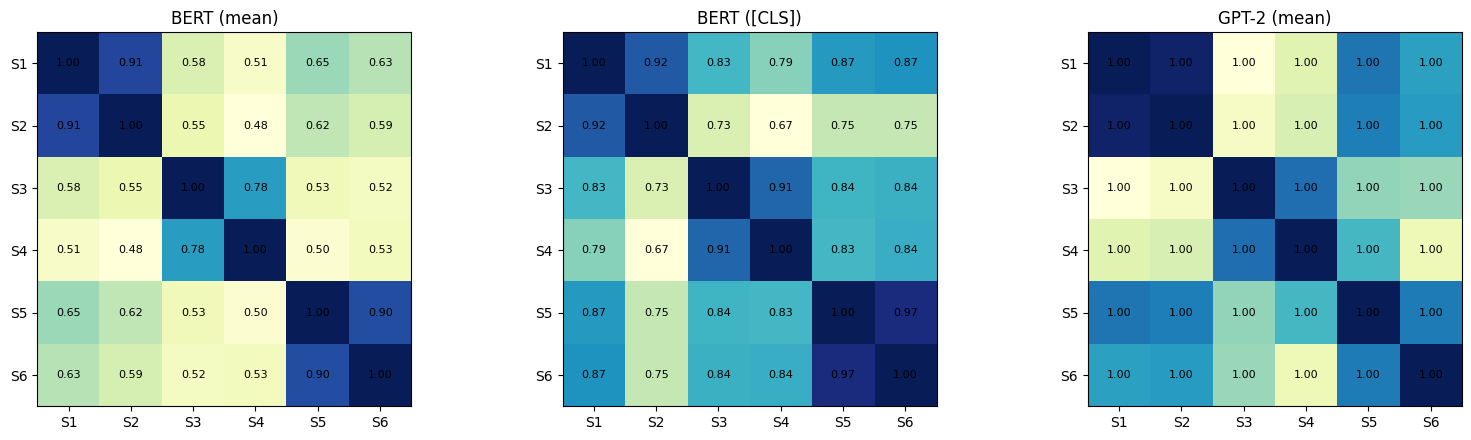

In [5]:
sims = {"BERT (mean)": cosine_similarity(bert_emb),
        "BERT ([CLS])": cosine_similarity(bert_cls),
        "GPT-2 (mean)": cosine_similarity(gpt2_emb)}

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (name, s) in zip(ax, sims.items()):
    im = a.imshow(s, cmap="YlGnBu", vmin=s.min(), vmax=1)
    a.set_xticks(range(len(labels))); a.set_xticklabels(labels)
    a.set_yticks(range(len(labels))); a.set_yticklabels(labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            a.text(j, i, f"{s[i,j]:.2f}", ha="center", va="center", fontsize=8)
    a.set_title(name)
plt.tight_layout(); plt.show()

In [6]:
# Paired sentences (S1,S2), (S3,S4), (S5,S6) are paraphrases -> should score higher than unrelated pairs
pairs = [(0, 1), (2, 3), (4, 5), (0, 2), (1, 4), (3, 5)]
rows = []
for i, j in pairs:
    rows.append((f"{labels[i]}-{labels[j]}", "paraphrase" if (i, j) in [(0, 1), (2, 3), (4, 5)] else "unrelated",
                 round(sims["BERT (mean)"][i, j], 3), round(sims["GPT-2 (mean)"][i, j], 3)))
display(pd.DataFrame(rows, columns=["pair", "type", "BERT cosine", "GPT-2 cosine"]))

,pair,type,BERT cosine,GPT-2 cosine
0,S1-S2,paraphrase,0.908,1.000
1,S3-S4,paraphrase,0.784,0.999
2,S5-S6,paraphrase,0.896,0.998
3,S1-S3,unrelated,0.582,0.995
4,S2-S5,unrelated,0.619,0.998
5,S4-S6,unrelated,0.527,0.996


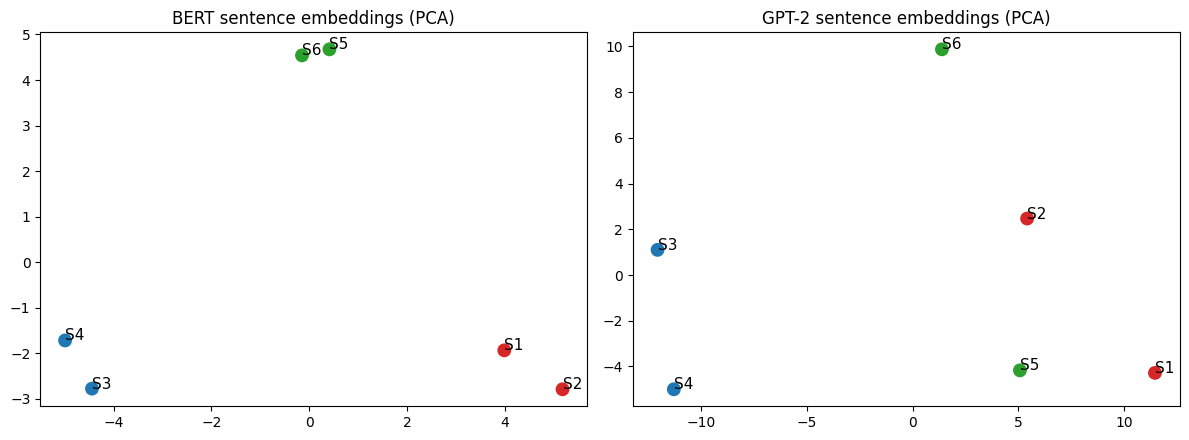

In [7]:
# 2-D visualisation of the embeddings
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
colors = ["tab:red", "tab:red", "tab:blue", "tab:blue", "tab:green", "tab:green"]
for a, (name, emb) in zip(ax, [("BERT", bert_emb), ("GPT-2", gpt2_emb)]):
    pts = PCA(n_components=2).fit_transform(emb)
    a.scatter(pts[:, 0], pts[:, 1], c=colors, s=80)
    for l, (x, y) in zip(labels, pts): a.annotate(l, (x, y), fontsize=11)
    a.set_title(f"{name} sentence embeddings (PCA)")
plt.tight_layout(); plt.show()

In [8]:
# Semantic search with BERT embeddings
query = ["Prices on the share market went down"]
q_emb = embed("bert-base-uncased", query, "mean")
scores = cosine_similarity(q_emb, bert_emb)[0]
for i in scores.argsort()[::-1][:3]:
    print(f"{scores[i]:.3f} | {sentences[i]}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


0.788 | The stock market fell sharply today.
0.739 | Shares dropped heavily in today's trading session.
0.596 | The cat is sleeping on the sofa.
